# Do the style features separate abstracts before and after ChatGPT?

We have no ground truth (no paper is known to be AI-written), so this notebook uses **publication year** as a proxy:
2020–2022 abstracts were written before ChatGPT (Nov 2022), and 2023–2025 abstracts may include LLM-assisted text.

A shift after 2022 is consistent with LLM use, but it is **not proof**: topics, templates and authors change too
(for example, many recent ISMIR papers study LLMs). Read every result below as "the features changed", not "the papers are AI-written".

Input: `data/processed/features_v1.csv`, from `python -m analysis.features` (one row per abstract).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import false_discovery_control, mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES_CSV = "../data/processed/features_v1.csv"
CHATGPT = 2022.5  # between the last pre and the first post year

# Colors from the dataviz reference palette (light surface).
SURFACE, TEXT, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, RED, CONTEXT = "#2a78d6", "#eb6834", "#e34948", "#d3d2cc"  # series 1, series 2, diverging +, context
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", RED])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

In [2]:
df = pd.read_csv(FEATURES_CSV)
df["post"] = df.year >= 2023
feature_cols = [c for c in df.columns if c not in ("paper_id", "year", "source", "post")]

# Features that are almost always 0 (rare entity types) add noise to the PCA: drop them.
rare = [c for c in feature_cols if (df[c] != 0).mean() < 0.05]
used = [c for c in feature_cols if c not in rare]
print(f"{len(df)} abstracts, {len(used)} features used")
print("Dropped (non-zero in < 5% of abstracts):", ", ".join(rare))
df.groupby("year").size().rename("abstracts").to_frame().T

655 abstracts, 44 features used
Dropped (non-zero in < 5% of abstracts): pos_INTJ, ent_EVENT_per_100_words, ent_FAC_per_100_words, ent_LANGUAGE_per_100_words, ent_LAW_per_100_words, ent_LOC_per_100_words, ent_MONEY_per_100_words, ent_QUANTITY_per_100_words, ent_WORK_OF_ART_per_100_words


year,2020,2021,2022,2023,2024,2025
abstracts,115,104,113,101,123,99


## 1. PCA

All features are standardized (mean 0, SD 1), so each counts the same.

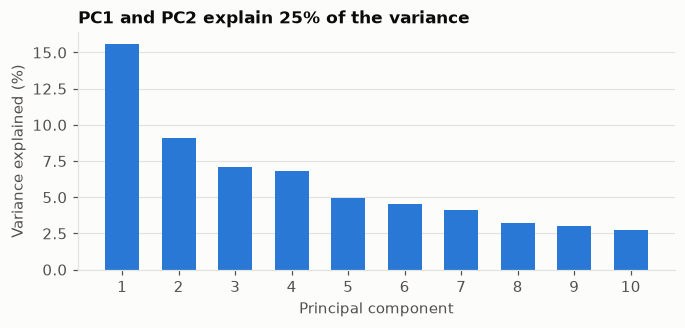

In [3]:
X = StandardScaler().fit_transform(df[used])
pca = PCA().fit(X)
pcs = pca.transform(X)
df["PC1"], df["PC2"] = pcs[:, 0], pcs[:, 1]
explained = 100 * pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 2.8))
k = 10
ax.bar(range(1, k + 1), explained[:k], color=BLUE, width=0.6)
ax.set(xlabel="Principal component", ylabel="Variance explained (%)", xticks=range(1, k + 1))
ax.grid(axis="x", visible=False)
ax.set_title(f"PC1 and PC2 explain {explained[:2].sum():.0f}% of the variance")
plt.show()

## 2. PC1 vs PC2, one panel per year

Gray: all 655 abstracts. Blue: the abstracts of that year. The cross is that year's mean.
If LLM use changed the style, the later panels should drift away from the earlier ones.

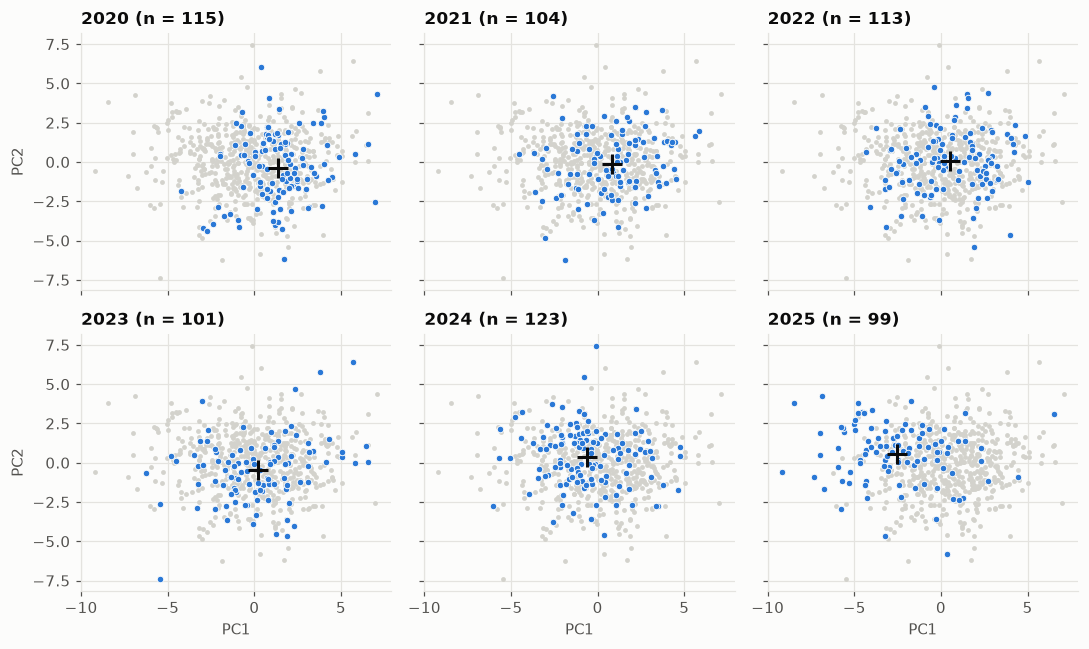

In [4]:
years = sorted(df.year.unique())
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex=True, sharey=True)
for ax, year in zip(axes.flat, years):
    sub = df[df.year == year]
    ax.scatter(df.PC1, df.PC2, s=10, color=CONTEXT, linewidths=0)
    ax.scatter(sub.PC1, sub.PC2, s=18, color=BLUE, edgecolors=SURFACE, linewidths=0.6)
    ax.scatter(sub.PC1.mean(), sub.PC2.mean(), marker="+", s=160, color=TEXT, linewidths=2)
    ax.set_title(f"{year} (n = {len(sub)})")
for ax in axes[1]:
    ax.set_xlabel("PC1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC2")
fig.tight_layout()
plt.show()

## 3. Timeline: mean position per year

Mean PC score per year with a 95% confidence interval. The dotted line is the 2020–2022 mean.

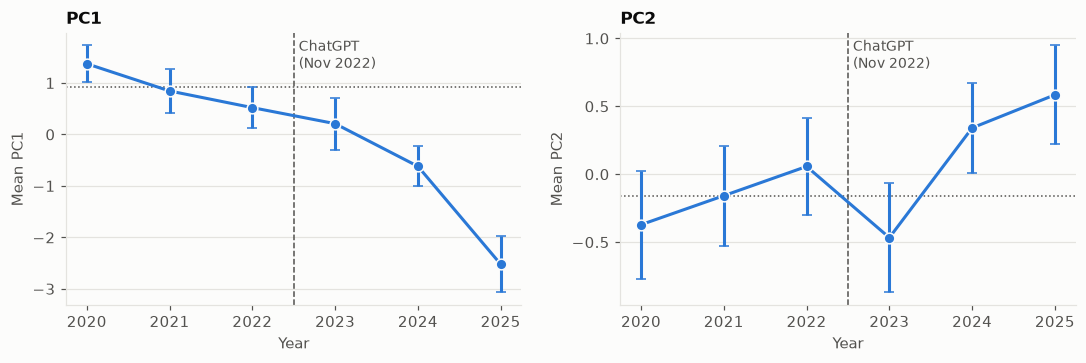

year,2020,2021,2022,2023,2024,2025
PC1,1.37,0.84,0.52,0.21,-0.62,-2.52
PC2,-0.37,-0.16,0.06,-0.47,0.34,0.58


In [5]:
def timeline(ax, column):
    stats = df.groupby("year")[column].agg(["mean", "sem"])
    ax.axvline(CHATGPT, color=MUTED, linestyle="--", linewidth=1)
    ax.axhline(df.loc[~df.post, column].mean(), color=MUTED, linestyle=":", linewidth=1)
    ax.errorbar(stats.index, stats["mean"], yerr=1.96 * stats["sem"], color=BLUE, linewidth=2,
                marker="o", markersize=7, markeredgecolor=SURFACE, capsize=3)
    ax.text(CHATGPT + 0.06, 0.98, "ChatGPT\n(Nov 2022)", transform=ax.get_xaxis_transform(),
            va="top", fontsize=9, color=MUTED)
    ax.set(xlabel="Year", ylabel=f"Mean {column}", xticks=stats.index)
    ax.grid(axis="x", visible=False)
    ax.set_title(column)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
timeline(axes[0], "PC1")
timeline(axes[1], "PC2")
fig.tight_layout()
plt.show()
df.groupby("year")[["PC1", "PC2"]].mean().round(2).T

## 4. What PC1 and PC2 measure

The 12 features with the largest loadings on each component. Red: the feature grows with the component; blue: it shrinks.

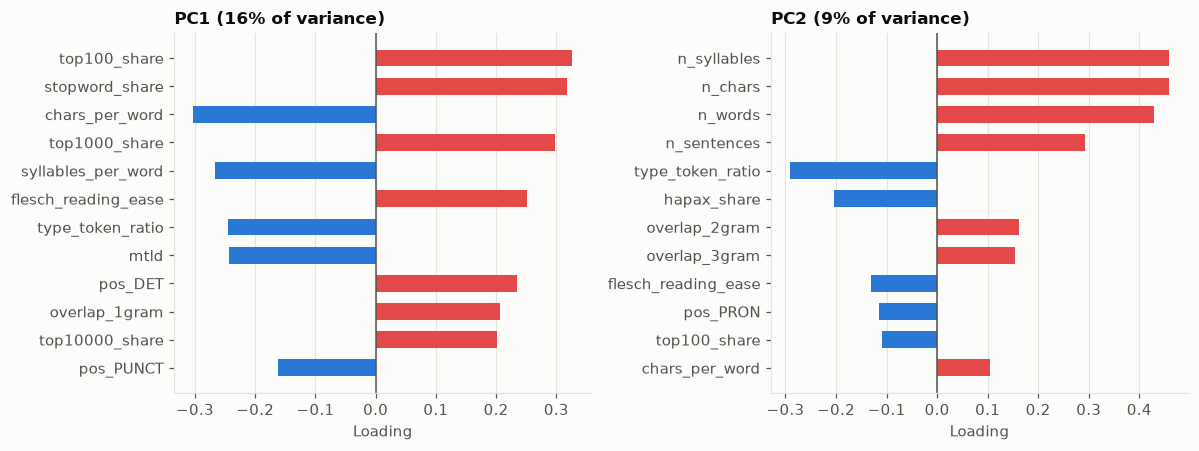

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, i in zip(axes, (0, 1)):
    loadings = pd.Series(pca.components_[i], index=used)
    top = loadings.reindex(loadings.abs().sort_values().index[-12:])
    ax.barh(top.index, top.values, color=np.where(top.values > 0, RED, BLUE), height=0.6)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set(xlabel="Loading")
    ax.set_title(f"PC{i + 1} ({explained[i]:.0f}% of variance)")
fig.tight_layout()
plt.show()

## 5. Which single features changed after 2022?

For each feature: the shift of the 2023–2025 mean from the 2020–2022 mean, in 2020–2022 standard deviations,
and a Mann-Whitney test. With this many tests some small p-values occur by chance, so the table also shows
q-values (Benjamini-Hochberg false discovery rate).

In [7]:
pre, post = df[~df.post], df[df.post]
drift = pd.DataFrame({
    "shift_sd": [(post[c].mean() - pre[c].mean()) / pre[c].std() for c in used],
    "p_value": [mannwhitneyu(pre[c], post[c]).pvalue for c in used],
}, index=used)
drift["q_value"] = false_discovery_control(drift.p_value)
drift = drift.reindex(drift.shift_sd.abs().sort_values(ascending=False).index)
print(f"{(drift.q_value < 0.05).sum()} of {len(drift)} features differ at q < 0.05")
drift.head(15).round(4)

20 of 44 features differ at q < 0.05


,shift_sd,p_value,q_value
top100_share,-0.8154,0.0000,0.0000
stopword_share,-0.7816,0.0000,0.0000
top1000_share,-0.7234,0.0000,0.0000
chars_per_word,0.6538,0.0000,0.0000
flesch_reading_ease,-0.5686,0.0000,0.0000
syllables_per_word,0.5516,0.0000,0.0000
pos_DET,-0.5443,0.0000,0.0000
mtld,0.5312,0.0000,0.0000
top10000_share,-0.4501,0.0000,0.0000
pos_PUNCT,0.4391,0.0000,0.0000


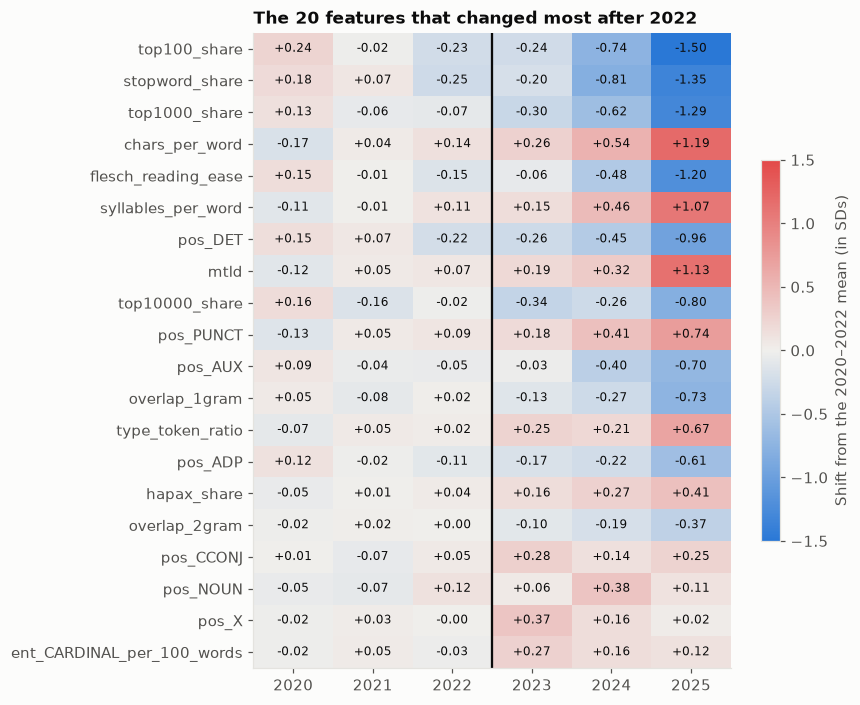

In [8]:
top = drift.index[:20]
by_year = df.groupby("year")[list(top)].mean()
shift = ((by_year - pre[top].mean()) / pre[top].std()).T
limit = np.abs(shift.values).max()

fig, ax = plt.subplots(figsize=(7, 7.5))
image = ax.imshow(shift.values, cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(years)), years)
ax.set_yticks(range(len(top)), top)
ax.grid(False)
for (r, c), value in np.ndenumerate(shift.values):
    ax.text(c, r, f"{value:+.2f}", ha="center", va="center", fontsize=8, color=TEXT)
ax.axvline(2.5, color=TEXT, linewidth=1.5)
fig.colorbar(image, ax=ax, shrink=0.6, label="Shift from the 2020–2022 mean (in SDs)")
ax.set_title("The 20 features that changed most after 2022")
plt.show()

## 6. How well do the features tell the two periods apart?

A logistic regression predicts "after 2022" from the features (5-fold cross-validation, AUC: 0.5 = chance, 1 = perfect).
This measures how much period signal the features carry. It does not say which papers are AI-written.

In [9]:
y = df.post.values
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
for name, columns in [("All features", used), ("PC1 + PC2 only", ["PC1", "PC2"])]:
    auc = cross_val_score(model, df[columns], y, cv=folds, scoring="roc_auc")
    print(f"{name:<15} AUC {auc.mean():.3f} ± {auc.std():.3f}")

All features    AUC 0.676 ± 0.060
PC1 + PC2 only  AUC 0.704 ± 0.025


## 7. Is the shift only from papers about AI?

Many recent ISMIR papers study LLMs, and their abstracts might differ just because of the topic.
Here we split each year into papers that mention an AI model anywhere in the text (from `disclosure_hits_v1.csv`) and papers that don't.
If the trend also shows in papers that never mention AI, topic alone does not explain it.

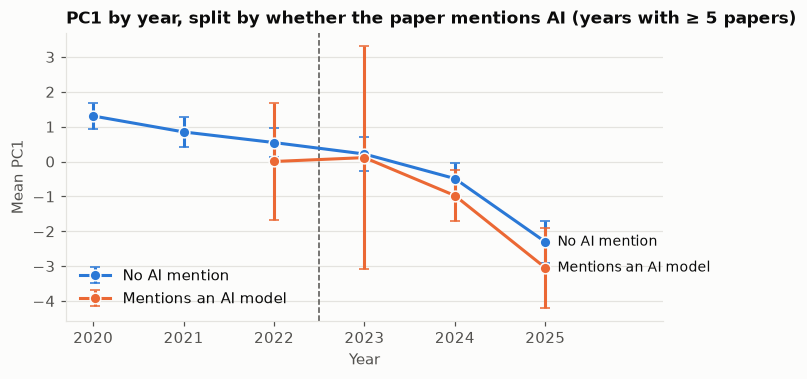

mean        size      
mentions_ai False True  False True 
year                               
2020         1.31  3.82   112     3
2021         0.85  0.68   101     3
2022         0.54  0.00   108     5
2023         0.22  0.11    94     7
2024        -0.49 -0.98    90    33
2025        -2.30 -3.05    70    29

In [10]:
hits = pd.read_csv("../data/processed/disclosure_hits_v1.csv")
ai_terms = "llm|chatgpt|gpt|generative_ai|claude|gemini"
df["mentions_ai"] = df.paper_id.isin(hits.loc[hits.terms.str.contains(ai_terms), "paper_id"])

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axvline(CHATGPT, color=MUTED, linestyle="--", linewidth=1)
for mentions, color, name in [(False, BLUE, "No AI mention"), (True, ORANGE, "Mentions an AI model")]:
    stats = df[df.mentions_ai == mentions].groupby("year").PC1.agg(["mean", "sem", "size"])
    stats = stats[stats["size"] >= 5]  # too few papers for a stable mean
    ax.errorbar(stats.index, stats["mean"], yerr=1.96 * stats["sem"], color=color, linewidth=2, marker="o",
                markersize=7, markeredgecolor=SURFACE, capsize=3, label=name)
    ax.annotate(name, (stats.index[-1], stats["mean"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=TEXT)
ax.set(xlabel="Year", ylabel="Mean PC1", xticks=sorted(df.year.unique()), xlim=(2019.7, 2026.3))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower left")
ax.set_title("PC1 by year, split by whether the paper mentions AI (years with ≥ 5 papers)")
plt.show()
df.groupby(["year", "mentions_ai"]).PC1.agg(["mean", "size"]).round(2).unstack()

## Findings (features_v1)

1. **No separate "AI" cluster.** PC1 and PC2 explain 25% of the variance, and every year overlaps with every other year.
   This is expected: LLM help is partial and mixed into human text, so it moves papers along a direction rather than into a new group.
2. **There is a clear time trend on PC1.** Lower PC1 means fewer very common words and stop words, longer words, more varied vocabulary
   (MTLD, type-token ratio) and a lower Flesch reading score. 20 of 44 features differ between the periods at q < 0.05.
3. **The trend started before ChatGPT, then sped up.** Mean PC1 fell from 1.37 (2020) to 0.52 (2022), then to −0.62 (2024) and −2.52 (2025).
   A plain before/after comparison therefore overstates the effect. A fair test compares 2023–2025 with the 2020–2022 trend
   extended forward (the approach of Kobak et al.).
4. **Papers about AI do not explain it.** Papers that never mention an AI model follow the same trend (2025: −2.30).
5. **The period signal is real but weak.** Predicting "after 2022" from the features gives AUC ≈ 0.70.

Next step: the synthetic abstracts (`analysis/generate.py`) give real LLM labels. If human → LLM moves abstracts in the same
PC1 direction as 2022 → 2025, that supports LLM influence. If it points elsewhere, the drift has another cause.